**Live cloud deployment:** [Open Titanic Passenger Survival Prediction System](https://ml-assignment--2-gd6kkhysuysojbbvijypvj.streamlit.app/)

Public access and predictions verified on 2026-10-22 (Asia/Karachi).

# Titanic Passenger Survival Prediction System
**Assignment 2 - Developing an End-to-End Machine Learning System**

**Student:** Muhammad Bilal Nawaz | **Registration:** SP24-BSE-070  
**Course:** AIC354 - Machine Learning Fundamentals | **Semester:** Fall 2026  
**Instructor:** Dr. Rao Muhammad Adeel Nawab | COMSATS University Islamabad, Lahore Campus

This notebook implements data collection, understanding, preprocessing and encoding, followed by the training, testing, application and feedback phases. All experiments and saved artifacts are produced by running the cells in order.

## Source, scope and reproducibility
Adapted from the assignment-provided [Titanic Recommended notebook](https://github.com/haqnawaz99/ml-teaching-notebooks), commit `c5f67db8361bd8953c4facf9e5ab98ce9242f314`. Original teaching material credits Mr. Mohsin Afzal and Dr. Rao Muhammad Adeel Nawab. This submission retains the source step sequence and SVC approach, with explicit changes below. Source material is credited; AI-assisted implementation was reviewed through executable checks.

Run **Kernel > Restart Kernel and Run All Cells** from this task folder. Install the parent `requirements-notebook.txt` first. Data are included locally, so training does not need network access. See `../PROVENANCE.json` for data hashes and `../README.md` for deployment and execution commands.

## Workflow
1. Import libraries
2. Load sample data
3. Understand and preprocess data
4. Extract/select features
5. Encode output and inputs
6. Training phase: split, fit and save
7. Testing phase: reload, predict and evaluate
8. Application phase: new input to prediction
9. Feedback phase: review findings and plan improvements
10. Generate the deployment app and verify its status

## Problem and fidelity to the provided code
Predict `Survived` (No=0, Yes=1) using `PClass`, `Gender`, `Sibling`, and `Embarked`. The supplied sample has 100 rows; this is not the full Titanic dataset. The source's category lists, label encoding, ordered 80/20 split and SVC settings are retained for a faithful reproduction.

Changes improve presentation and deployment reproducibility: schema checks, an encoder/model bundle, additional metrics, persisted per-row predictions and honest feedback status. No model tuning is performed. The original notebook is also executed separately in the reference directory.

### Step 1: Import Libraries

In [1]:
TASK = 'Titanic'

from pathlib import Path
import hashlib, json, pickle, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             balanced_accuracy_score, roc_auc_score, RocCurveDisplay)
BASE = Path.cwd()
if not (BASE / 'data').is_dir():
    candidate = BASE / TASK
    if not candidate.is_dir():
        candidate = BASE / 'submission' / TASK
    BASE = candidate
assert (BASE / 'data').is_dir(), 'Open this notebook from its task folder or submission folder.'
for name in ['models', 'outputs']:
    (BASE / name).mkdir(exist_ok=True)
pd.set_option('display.max_rows', 16)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('Python:', platform.python_version(), '| scikit-learn:', sklearn.__version__)

Python: 3.14.6 | scikit-learn: 1.9.1


### Step 2: Load Sample Data

In [2]:
source_path = BASE / 'data/titanic.csv'
raw = pd.read_csv(source_path)
assert raw.shape == (100, 5)
print('Rows, columns:', raw.shape)
print('Source SHA256:', hashlib.sha256(source_path.read_bytes()).hexdigest())
display(raw.head(10))

Rows, columns: (100, 5)
Source SHA256: a63e6a9e933cb459d24855705addc6161b26970070444a5bee7d879e915731a8


,PClass,Gender,Sibling,Embarked,Survived
0,Third,Male,One,Southampton,No
1,Second,Female,Zero,Southampton,Yes
2,Third,Male,Zero,Southampton,No
3,Third,Female,Three,Southampton,Yes
4,Third,Male,Zero,Queenstown,No
5,First,Female,Three,Southampton,Yes
6,Third,Male,Zero,Southampton,No
7,Third,Male,Zero,Southampton,Yes
8,First,Male,Zero,Southampton,No
9,Second,Male,Zero,Southampton,Yes


### Step 3: Understand and Pre-process Sample Data
#### Step 3.1: Understand Sample Data

In [3]:
raw.info()
display(raw.describe(include='all'))
display(raw.isna().sum().to_frame('Missing values'))
display(raw['Survived'].value_counts().to_frame('Rows'))
print('Repeated complete feature-label rows:', int(raw.duplicated().sum()))

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   PClass    100 non-null    str  
 1   Gender    100 non-null    str  
 2   Sibling   100 non-null    str  
 3   Embarked  100 non-null    str  
 4   Survived  100 non-null    str  
dtypes: str(5)
memory usage: 6.7 KB


,PClass,Gender,Sibling,Embarked,Survived
count,100,100,100,100,100
unique,3,2,4,3,2
top,Third,Male,Zero,Southampton,No
freq,60,58,59,75,50


,Missing values
PClass,0
Gender,0
Sibling,0
Embarked,0
Survived,0


,Rows
Survived,
No,50
Yes,50


Repeated complete feature-label rows: 56


#### Step 3.2: Pre-process Sample Data
The source sample is already preprocessed. Verify missing values and category validity rather than silently assuming cleanliness. Repeated rows are retained to reproduce the teaching experiment: these are repeated combinations of coarse attributes, with no passenger identifier to establish whether they represent duplicate people. Such repetitions limit how strongly test accuracy can be interpreted.

In [4]:
assert not raw.isna().any().any()
category_schema = {
    'PClass': ['First','Second','Third'], 'Gender': ['Male','Female'],
    'Sibling': ['Zero','One','Two','Three'],
    'Embarked': ['Southampton','Cherbourg','Queenstown']}
for name, values in category_schema.items():
    assert set(raw[name]) <= set(values)
assert set(raw['Survived']) == {'No','Yes'}

### Step 4: Feature Extraction
The instructor has already selected the four features. Keep their order consistent throughout.

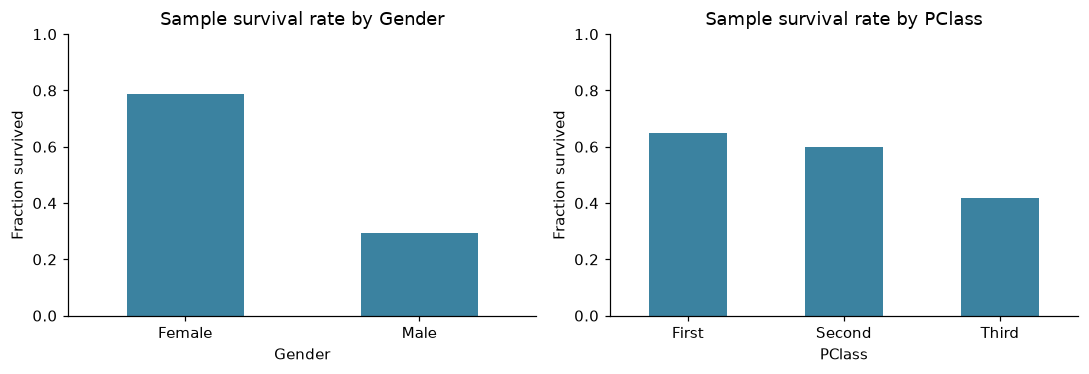

In [5]:
FEATURES = ['PClass', 'Gender', 'Sibling', 'Embarked']
TARGET = 'Survived'
sample = raw[FEATURES + [TARGET]].copy()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, field in zip(axes, ['Gender','PClass']):
    summary = sample.assign(SurvivalRate=(sample[TARGET] == 'Yes').astype(int)).groupby(field)['SurvivalRate'].mean()
    summary.plot.bar(ax=ax, color='#3b82a0', rot=0)
    ax.set(title='Sample survival rate by ' + field, ylabel='Fraction survived', ylim=(0,1))
plt.tight_layout(); plt.savefig(BASE / 'outputs/data_overview.png'); plt.show()

### Step 5: Label Encoding the Sample Data
#### Step 5.1: Train the Label Encoders
Fixed category lists match the instructor. LabelEncoder sorts strings alphabetically: `Sibling` codes are **One=0, Three=1, Two=2, Zero=3**, not the sibling counts. This is preserved for reproduction and recorded as a modeling limitation.

In [6]:
encoders = {name: LabelEncoder().fit(values) for name, values in category_schema.items()}
target_encoder = LabelEncoder().fit(['Yes','No'])
for name, encoder in {**encoders, TARGET: target_encoder}.items():
    print(name, dict(zip(encoder.classes_.tolist(), range(len(encoder.classes_)))))

PClass {'First': 0, 'Second': 1, 'Third': 2}
Gender {'Female': 0, 'Male': 1}
Sibling {'One': 0, 'Three': 1, 'Two': 2, 'Zero': 3}
Embarked {'Cherbourg': 0, 'Queenstown': 1, 'Southampton': 2}
Survived {'No': 0, 'Yes': 1}


#### Steps 5.2-5.3: Encode Output and Inputs

In [7]:
encoded = pd.DataFrame(index=sample.index)
for name in FEATURES:
    encoded[name] = encoders[name].transform(sample[name])
encoded[TARGET] = target_encoder.transform(sample[TARGET])
encoded.to_csv(BASE / 'outputs/sample-data-encoded.csv', index_label='source_row')
display(encoded.head(10))

,PClass,Gender,Sibling,Embarked,Survived
0,2,1,0,2,0
1,1,0,3,2,1
2,2,1,3,2,0
3,2,0,1,2,1
4,2,1,3,1,0
5,0,0,1,2,1
6,2,1,3,2,0
7,2,1,3,2,1
8,0,1,3,2,0
9,1,1,3,2,1


### Step 6: Execute the Training Phase
#### Steps 6.1-6.2: Split and separate inputs/labels
Preserve the original settings: first 80 rows train, last 20 rows test (`shuffle=False`). `random_state=0` has no effect without shuffling. Order bias is a limitation; this is reproduction, not a claim that this split is optimal.

In [8]:
train, test = train_test_split(encoded, test_size=0.2, random_state=0, shuffle=False)
train_idx, test_idx = train.index, test.index
X_train, X_test = train[FEATURES], test[FEATURES]
y_train, y_test = train[TARGET], test[TARGET]
assert set(train_idx).isdisjoint(test_idx)

#### Step 6.3: Train the Support Vector Classifier

In [9]:
model = SVC(gamma='auto', random_state=0)
model.fit(X_train, y_train)
print(model)

SVC(gamma='auto', random_state=0)


In [10]:
print('Training inputs:', X_train.shape, '| Testing inputs:', X_test.shape)
display(pd.DataFrame({'Train': y_train.value_counts(), 'Test': y_test.value_counts()}).sort_index())
encoded.loc[train_idx].to_csv(BASE / 'outputs/training-data-encoded.csv', index_label='source_row')
encoded.loc[test_idx].to_csv(BASE / 'outputs/testing-data-encoded.csv', index_label='source_row')

Training inputs: (80, 4) | Testing inputs: (20, 4)


,Train,Test
Survived,,
0,40,10
1,40,10


#### Step 6.4: Save the Trained Model
Save model, encoders, feature order, target labels, source and package versions together. Inference must reuse exactly the training transformations. Only load trusted model files: pickle can execute code.

In [11]:
bundle = {'task': TASK, 'features': FEATURES, 'model': model, 'encoders': encoders,
          'labels': {0: "Did not survive", 1: "Survived"},
          'source_url': "https://github.com/haqnawaz99/ml-teaching-notebooks",
          'sklearn_version': sklearn.__version__, 'training_rows': len(X_train),
          'observed_ranges': {name: [float(sample.loc[train_idx,name].min()), float(sample.loc[train_idx,name].max())] for name in [] } }
model_path = BASE / 'models/model_bundle.pkl'
with model_path.open('wb') as stream:
    pickle.dump(bundle, stream)
print('Saved:', model_path.name)

Saved: model_bundle.pkl


### Step 7: Execute the Testing Phase
#### Steps 7.1-7.3: Reload model and predict held-out inputs
Test features/labels were separated at the split. Reload from disk and compare predictions against the in-memory model to verify serialization.

In [12]:
with model_path.open('rb') as stream:
    loaded = pickle.load(stream)
predictions = loaded['model'].predict(X_test)
np.testing.assert_array_equal(predictions, model.predict(X_test))
prediction_table = sample.loc[test_idx].copy()
prediction_table['Actual_binary'] = y_test
prediction_table['Predicted_binary'] = predictions
prediction_table['Correct'] = predictions == y_test.to_numpy()
prediction_table.to_csv(BASE / 'outputs/model-predictions.csv', index_label='source_row')
display(prediction_table.head(12))

,PClass,Gender,Sibling,Embarked,Survived,Actual_binary,Predicted_binary,Correct
80,Third,Male,Two,Southampton,No,0,0,True
81,Third,Female,Zero,Southampton,Yes,1,1,True
82,Third,Male,Zero,Southampton,No,0,0,True
83,First,Male,One,Southampton,Yes,1,0,False
84,Second,Male,Zero,Southampton,No,0,0,True
85,Third,Female,One,Queenstown,Yes,1,1,True
86,Second,Male,Zero,Southampton,No,0,0,True
87,First,Female,One,Southampton,Yes,1,1,True
88,Third,Male,Zero,Southampton,No,0,0,True
89,Second,Female,Zero,Southampton,Yes,1,1,True


#### Steps 7.4-7.5: Accuracy and Detailed Evaluation
Precision, recall and F1 below treat class 1 as positive. Compare accuracy with a baseline fitted to the training majority. ROC AUC uses SVC decision scores, not calibrated probabilities. Test outcomes describe this particular sample and split.

,Result
accuracy,0.80
precision,1.00
recall,0.60
f1,0.75
balanced_accuracy,0.80
roc_auc,0.81
majority_baseline_accuracy,0.50
train_rows,80.00
test_rows,20.00


                 precision    recall  f1-score   support

Did not survive       0.71      1.00      0.83        10
       Survived       1.00      0.60      0.75        10

       accuracy                           0.80        20
      macro avg       0.86      0.80      0.79        20
   weighted avg       0.86      0.80      0.79        20



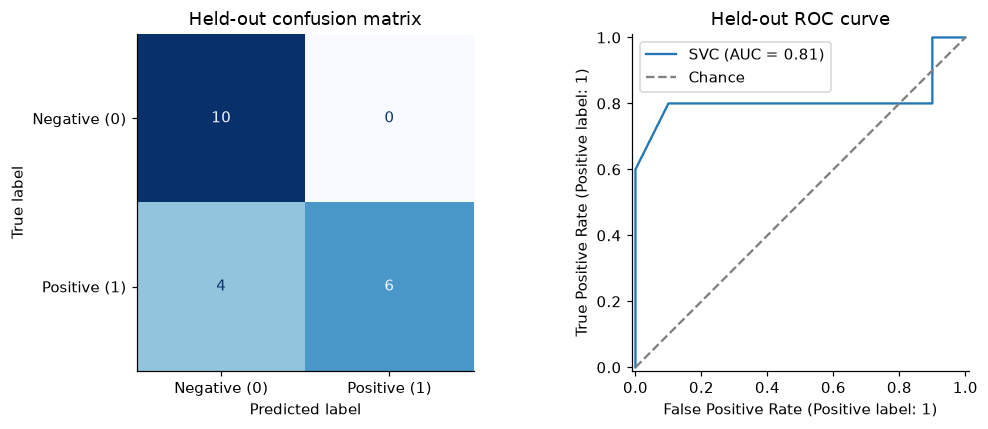

**Observed result:** 16/20 correct (80.0% accuracy), versus 50.0% majority baseline. Confusion counts: TN=10, FP=0, FN=4, TP=6. Positive-class recall=60.0%; F1=0.750. These are measured outputs, not an expected-score target.

In [13]:
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
scores = loaded['model'].decision_function(X_test)
metrics = {
    'accuracy': float(accuracy_score(y_test, predictions)),
    'precision': float(precision_score(y_test, predictions, zero_division=0)),
    'recall': float(recall_score(y_test, predictions, zero_division=0)),
    'f1': float(f1_score(y_test, predictions, zero_division=0)),
    'balanced_accuracy': float(balanced_accuracy_score(y_test, predictions)),
    'roc_auc': float(roc_auc_score(y_test, scores)),
    'majority_baseline_accuracy': float(accuracy_score(y_test, baseline.predict(X_test))),
    'train_rows': len(X_train), 'test_rows': len(X_test),
    'confusion_matrix': confusion_matrix(y_test, predictions, labels=[0,1]).tolist()
}
display(pd.Series({k:v for k,v in metrics.items() if k != 'confusion_matrix'}, name='Result').to_frame())
print(classification_report(y_test, predictions, labels=[0,1], target_names=[bundle['labels'][0], bundle['labels'][1]], zero_division=0))
(BASE / 'outputs/metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
bundle['metrics'] = metrics
with model_path.open('wb') as stream:
    pickle.dump(bundle, stream)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=[0,1], display_labels=['Negative (0)','Positive (1)'], ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Held-out confusion matrix')
RocCurveDisplay.from_predictions(y_test, scores, ax=axes[1], name='SVC')
axes[1].plot([0,1], [0,1], '--', color='gray', label='Chance'); axes[1].legend()
axes[1].set_title('Held-out ROC curve')
plt.tight_layout(); plt.savefig(BASE / 'outputs/evaluation.png'); plt.show()
tn, fp, fn, tp = metrics['confusion_matrix'][0] + metrics['confusion_matrix'][1]
display(Markdown(f"**Observed result:** {int((predictions == y_test).sum())}/{len(y_test)} correct "
    f"({metrics['accuracy']:.1%} accuracy), versus {metrics['majority_baseline_accuracy']:.1%} majority baseline. "
    f"Confusion counts: TN={tn}, FP={fp}, FN={fn}, TP={tp}. Positive-class recall={metrics['recall']:.1%}; "
    f"F1={metrics['f1']:.3f}. These are measured outputs, not an expected-score target."))

### Step 8: Execute the Application Phase
#### Steps 8.1-8.5: Input, feature vector, encoding, reload and prediction
The deterministic example allows unattended Run All. Change the four values to explore another case. The web app provides interactive widgets. No model is fitted during prediction.

In [14]:
user_values = {'PClass': 'First', 'Gender': 'Male', 'Sibling': 'Zero', 'Embarked': 'Queenstown'}
user_input = pd.DataFrame([user_values], columns=FEATURES)
unseen = user_input.copy()
with model_path.open('rb') as stream:
    deployed_bundle = pickle.load(stream)
for name, encoder in deployed_bundle['encoders'].items():
    assert unseen.at[0,name] in encoder.classes_, 'Unknown category'
    unseen[name] = encoder.transform(unseen[name])
prediction = int(deployed_bundle['model'].predict(unseen)[0])
display(user_input)
display(unseen)
print('Prediction:', deployed_bundle['labels'][prediction], '(class', prediction, ')')

,PClass,Gender,Sibling,Embarked
0,First,Male,Zero,Queenstown


,PClass,Gender,Sibling,Embarked
0,0,1,3,1


Prediction: Survived (class 1 )


### Step 9: Execute the Feedback Phase
#### Step 9.1: Collect Feedback from Users and Domain Experts
No external user/domain-expert feedback has yet been collected. The observations below come from local execution and evaluation, not invented interviews. A blank feedback template is saved for later review; real entries should record case, predicted class, verified outcome, reviewer role and proposed action without personal data.

**Current limitations:** A 100-row teaching sample is small; repeated coarse input combinations can occur in both subsets. An ordered split may reflect row-order artifacts. Alphabetic label codes impose artificial numeric distances, especially for Sibling and Embarked. Observed associations do not establish historical causal effects.

#### Step 9.2: Potential Improvements
- Review false positives and false negatives in the saved per-row predictions.
- Validate on additional independent data before claiming generalization.
- Compare representations and SVC settings using cross-validation within training data; preserve a separate final evaluation set.
- Collect usability feedback on units, category descriptions and validation messages.

#### Step 9.3: Act on Feedback
Implemented engineering improvements: saved preprocessing, fixed feature order, explicit input validation, honest class labels and reload consistency checks. No post-test retraining is performed or claimed to improve accuracy. A future model update requires documented feedback and fresh evaluation. 

In [15]:
feedback_columns = ['case_id','reviewer_role','predicted_class','verified_outcome','comment','proposed_action']
feedback_path = BASE / 'outputs/feedback_template.csv'
if not feedback_path.exists():
    pd.DataFrame(columns=feedback_columns).to_csv(feedback_path, index=False)
mistakes = prediction_table.loc[~prediction_table['Correct']]
print('Held-out errors available for review:', len(mistakes))
display(mistakes.head(10))
print('Real external feedback collected: 0; template:', feedback_path.name)

Held-out errors available for review: 4


,PClass,Gender,Sibling,Embarked,Survived,Actual_binary,Predicted_binary,Correct
83,First,Male,One,Southampton,Yes,1,0,False
93,First,Male,One,Southampton,Yes,1,0,False
97,Third,Male,One,Southampton,Yes,1,0,False
99,Third,Male,One,Southampton,Yes,1,0,False


Real external feedback collected: 0; template: feedback_template.csv


### Step 10: Deploy the Model as a Public Web App
The next cell writes the complete Streamlit entry point. It loads the trained bundle and reuses its encoders/pipeline. The UI supplies exactly the four declared features.

Run from this task folder: `python -m streamlit run app.py`.

Upload the submission folder contents to a GitHub repository. In Streamlit Community Cloud create a public app, choose the repository, select this task's `app.py` and use Python 3.14. Deploy each task as a separate app from the same repository. The pinned dependency files accompany both apps. Full instructions are in the parent README. After verifying the public prediction, replace the first cell's pending status with the actual URL and update `deployment_status.json`.

Local execution alone does not satisfy the cloud requirement. The instructor's demo URL must not be substituted for a personal deployment.

In [16]:
app_source = '"""Generated by Step 10 of the corresponding assignment notebook."""\nfrom pathlib import Path\nimport math\nimport pickle\nimport pandas as pd\nimport streamlit as st\n\nTASK = \'Titanic\'\nBASE = Path(__file__).resolve().parent\nst.set_page_config(page_title=TASK.replace(\'_\', \' \') + \' Predictor\', page_icon=\'📊\', layout=\'centered\')\n\n@st.cache_resource\ndef load_bundle(model_file):\n    with Path(model_file).open(\'rb\') as stream:\n        return pickle.load(stream)\n\ndef predict(values, bundle):\n    if set(values) != set(bundle[\'features\']):\n        raise ValueError(\'Provide exactly the four required inputs.\')\n    row = pd.DataFrame([values], columns=bundle[\'features\'])\n    if TASK == \'Heart_Disease\':\n        for field, low, high in [(\'age\', 1, 120), (\'thalach\', 30, 250)]:\n            value = float(row.at[0, field])\n            if not math.isfinite(value) or not low <= value <= high or not value.is_integer():\n                raise ValueError(f\'{field} must be a whole number from {low} to {high}.\')\n            row[field] = value\n    for field, encoder in bundle[\'encoders\'].items():\n        if row.at[0, field] not in encoder.classes_:\n            raise ValueError(f\'Invalid category for {field}.\')\n        row[field] = encoder.transform(row[field])\n    label = int(bundle[\'model\'].predict(row)[0])\n    return label, bundle[\'labels\'][label]\n\nst.title(\'Titanic Survival Predictor\' if TASK == \'Titanic\' else \'Heart Disease Predictor\')\nst.caption(\'AIC354 · Assignment 2 · Muhammad Bilal Nawaz · SP24-BSE-070\')\nbundle = load_bundle(str(BASE / \'models/model_bundle.pkl\'))\nif TASK == \'Heart_Disease\':\n    st.info(\'Educational demonstration using historical UCI data. This is not a medical diagnosis.\')\n    st.write(\'Enter four attributes to run the trained classifier.\')\nelse:\n    st.write(\'Explore a classifier trained on the instructor’s 100-passenger teaching sample.\')\n\nwith st.form(\'prediction_form\'):\n    if TASK == \'Titanic\':\n        values = {\n            \'PClass\': st.selectbox(\'Passenger class\', [\'First\', \'Second\', \'Third\']),\n            \'Gender\': st.selectbox(\'Gender\', [\'Male\', \'Female\']),\n            \'Sibling\': st.selectbox(\'Siblings / spouses aboard\', [\'Zero\', \'One\', \'Two\', \'Three\']),\n            \'Embarked\': st.selectbox(\'Embarkation port\', [\'Southampton\', \'Cherbourg\', \'Queenstown\'])\n        }\n    else:\n        pain = {1: \'Typical angina\', 2: \'Atypical angina\', 3: \'Non-anginal pain\', 4: \'Asymptomatic\'}\n        values = {\n            \'age\': st.number_input(\'Age (years)\', min_value=1, max_value=120, value=54, step=1),\n            \'cp\': st.selectbox(\'Chest-pain type\', [1, 2, 3, 4], format_func=lambda x: pain[x]),\n            \'thalach\': st.number_input(\'Maximum heart rate achieved (beats/min)\', min_value=30, max_value=250, value=150, step=1),\n            \'exang\': st.selectbox(\'Exercise-induced angina\', [0, 1], format_func=lambda x: \'Yes\' if x else \'No\')\n        }\n    submitted = st.form_submit_button(\'Predict\', type=\'primary\')\nif submitted:\n    try:\n        label, wording = predict(values, bundle)\n        st.success(\'Model prediction: \' + wording)\n        st.caption(\'Predicted class: \' + str(label) + \'. This is a class label, not a probability.\')\n        if TASK == \'Heart_Disease\' and any(not bounds[0] <= values[field] <= bounds[1] for field, bounds in bundle[\'observed_ranges\'].items()):\n            st.warning(\'An input is outside the training data range; this prediction may be unreliable.\')\n    except (ValueError, TypeError) as error:\n        st.error(str(error))\nwith st.expander(\'Model and evaluation\'):\n    st.write(\'Inputs:\', \', \'.join(bundle[\'features\']))\n    st.write(\'Held-out test accuracy:\', f"{bundle[\'metrics\'][\'accuracy\']:.1%}")\n    st.write(\'Test rows:\', bundle[\'metrics\'][\'test_rows\'])\n    st.write(\'Small historical datasets limit generalization. No live feedback has been used to retrain this model.\')\n    st.markdown(\'[Data and notebook source](\' + bundle[\'source_url\'] + \')\')\nst.caption(\'Inputs are used for this prediction only; the app does not write patient or passenger records.\')\n'
(BASE / 'app.py').write_text(app_source, encoding='utf-8')
print('Generated app.py:', len(app_source), 'characters')

Generated app.py: 4035 characters


In [17]:
status_path = BASE.parent / 'deployment_status.json'
status = json.loads(status_path.read_text(encoding='utf-8')) if status_path.exists() else {}
print(json.dumps(status.get(TASK, {'status':'pending', 'url':None}), indent=2))
assert list(bundle['features']) == FEATURES and len(FEATURES) == 4
assert set(train_idx).isdisjoint(test_idx)
assert model_path.exists() and (BASE / 'app.py').exists()
print('Local notebook checks passed. Cloud verification is a separate requirement.')

{
  "status": "deployed_and_verified",
  "url": "https://ml-assignment--2-gd6kkhysuysojbbvijypvj.streamlit.app/",
  "verified": true,
  "verified_date": "2026-10-22",
  "timezone": "Asia/Karachi",
  "public_access_without_sign_in": true,
  "prediction_tests": [
    {
      "inputs": {
        "PClass": "First",
        "Gender": "Male",
        "Sibling": "Zero",
        "Embarked": "Southampton"
      },
      "local_class": 1,
      "cloud_class": 1,
      "cloud_result": "Survived"
    },
    {
      "inputs": {
        "PClass": "First",
        "Gender": "Female",
        "Sibling": "Zero",
        "Embarked": "Southampton"
      },
      "local_class": 1,
      "cloud_class": 1,
      "cloud_result": "Survived"
    }
  ],
  "repository": "https://github.com/M-Bilal-cyber/ML-Assignment--2",
  "entrypoint": "Titanic/app.py",
  "local_model_sha256_at_verification": "25491fee9e7845d5f59115ef42ef385cf513385f57ec995afb27f994b72086bb",
  "evidence_file": "deployment_evidence/titanic_clo

## Verified cloud deployment

Public URL: https://ml-assignment--2-gd6kkhysuysojbbvijypvj.streamlit.app/

Verified on 2026-10-22 in a separate browser without signing in. Both a default-input prediction and a changed-input prediction matched the saved local model. Inputs and expected/observed results are recorded in `../deployment_status.json`; screenshots are in `../deployment_evidence/`. These are deployment smoke tests, not new accuracy estimates.

## Conclusion
Data were loaded, inspected and encoded; an SVC was trained and evaluated; the model and transformations were saved and reloaded for inference; feedback and limitations were documented; and a deployment application was generated. The measured evaluation above is reproducible from the bundled data. Cloud completion is tracked separately at the top of this notebook.